# P43: recovering `local_tol`'s decayed-tail losses
Regenerates the README figures. Inputs: `data/` (variant metrics, harness summary, local_tol candidate table, lost-star tables, timing) and the scorecard runs named in `analysis.py` (`runs/p43/sc/`, `benchmarks/baselines/*_v7_tables`); the example panels refit stars from `data/smarts_dev` with the Stage-1 cache in `runs/p43/stage1_cache/`.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display
HERE = Path.cwd() if (Path.cwd() / 'analysis.py').exists() else Path('reports/2026-11-15_p43-decayed-tail')
sys.path.insert(0, str(HERE))
import analysis as A
pd.set_option('display.width', 200)

## Diagnosis: what fails on local_tol's lost stars
One row per correct candidate of T32's 30 lost star-modes (`diag_lost2.py`). `hs` = sign of each tooth's fitted height, `vs` = tooth within tolerance.

In [2]:
display(pd.read_csv(A.DATA / 'diag_lost_candidates.csv').head(40))

,star,mode,Pt,fin,P,failed,nwin,trim,fvt,fvt_pos,fph,snr,hl,hs,vs
0,3313,fu,0.69,none,0.79,HL,4,3,1.00,1.00,1.00,2.40,-0.013,++++,vvvv
1,3313,fu,0.69,none,0.77,"f_positive_heights,f_vertex_tol",4,3,0.50,0.67,0.75,2.23,0.005,+++-,vv..
2,3313,fu,0.69,none,0.77,f_vertex_tol,4,3,0.00,0.00,1.00,1.77,0.005,++++,....
3,3313,fu,0.69,none,0.78,"f_positive_heights,f_vertex_tol",4,3,0.00,0.00,0.75,1.43,0.005,+++-,....
4,3313,fu,0.69,none,0.82,"f_positive_heights,snr,HL,f_vertex_tol",4,3,0.00,0.00,0.50,0.72,-0.031,++--,....
5,3890,fu,0.79,none,0.83,f_vertex_tol,8,0,0.43,0.33,0.88,2.13,-0.032,+++++-+,v...vv.
6,3890,fu,0.79,none,0.78,"HL,f_vertex_tol",5,3,0.50,0.67,0.80,2.57,-0.224,++-+,vv..
7,3890,fu,0.79,none,0.80,"HL,f_vertex_tol",8,0,0.43,0.50,0.88,1.93,-0.093,+++++-+,vv.v...
8,8023,fu,1.53,none,1.46,f_positive_heights,4,1,1.00,1.00,0.75,1.59,0.118,+++-,vvvv
9,8023,fu,1.53,none,1.43,f_vertex_tol,6,2,0.40,0.40,1.00,4.44,0.061,+++++,vv...


## Scorecard and harness tables

In [3]:
display(pd.read_csv(A.DATA / 'variant_metrics.csv').round(3))
display(pd.read_csv(A.DATA / 'harness_summary.csv').round(3))

,variant,mode,n,success,wrong,alias,none,precision,gained_vs_tol,lost_vs_tol,none_to_wrong_vs_tol,wrong_to_none_vs_tol,gained_vs_v7,lost_vs_v7,none_to_wrong_vs_v7,wrong_to_none_vs_v7
0,local_screen2,fullyear,1000,0.251,0.088,0.014,0.647,0.711,21.0,18.0,19.0,0.0,NaN,NaN,NaN,NaN
1,local_screen2,assigned,1000,0.147,0.055,0.009,0.789,0.697,9.0,7.0,10.0,4.0,NaN,NaN,NaN,NaN
2,local_tol,fullyear,1000,0.248,0.067,0.013,0.672,0.756,NaN,NaN,NaN,NaN,18.0,21.0,0.0,19.0
3,local_tol,assigned,1000,0.145,0.048,0.011,0.796,0.711,NaN,NaN,NaN,NaN,7.0,9.0,4.0,10.0
4,local_tol_tail,fullyear,1000,0.257,0.072,0.013,0.658,0.751,9.0,0.0,5.0,0.0,22.0,16.0,4.0,19.0
5,local_tol_tail,assigned,1000,0.153,0.057,0.010,0.780,0.695,8.0,0.0,8.0,0.0,12.0,6.0,10.0,9.0
6,local_tol_tail_snr0,fullyear,1000,0.250,0.068,0.010,0.672,0.762,7.0,5.0,2.0,1.0,21.0,22.0,2.0,21.0
7,local_tol_tail_snr0,assigned,1000,0.150,0.049,0.009,0.792,0.721,6.0,1.0,1.0,1.0,11.0,8.0,4.0,10.0
8,local_tol_norej_tail_snr0,fullyear,1000,0.256,0.064,0.010,0.670,0.776,21.0,13.0,4.0,6.0,29.0,24.0,4.0,26.0
9,local_tol_norej_tail_snr0,assigned,1000,0.150,0.049,0.009,0.792,0.721,9.0,4.0,4.0,4.0,14.0,11.0,5.0,11.0


,mode,variant,n,success,wrong,none,alias,fit_s
0,fullyear,local_tol,1000,0.248,0.067,0.672,0.013,0.134
1,fullyear,local_tol_pos,1000,0.249,0.070,0.668,0.013,0.133
2,fullyear,local_tol_tail,1000,0.257,0.072,0.658,0.013,0.133
3,fullyear,local_tol_norej,1000,0.277,0.113,0.590,0.020,0.106
4,fullyear,local_tol_norej_tail,1000,0.288,0.133,0.558,0.021,0.106
5,fullyear,local_tol_norej_pos,1000,0.278,0.123,0.579,0.020,0.106
6,fullyear,local_tol_tail_rh,1000,0.256,0.074,0.655,0.015,0.221
7,fullyear,local_tol_norej_rh,1000,0.277,0.102,0.602,0.019,0.165
8,fullyear,local_tol_snr0,1000,0.242,0.066,0.682,0.010,0.129
9,fullyear,local_tol_tail_snr0,1000,0.250,0.068,0.672,0.010,0.128


## Success / alias / wrong by period bin (scorecards)

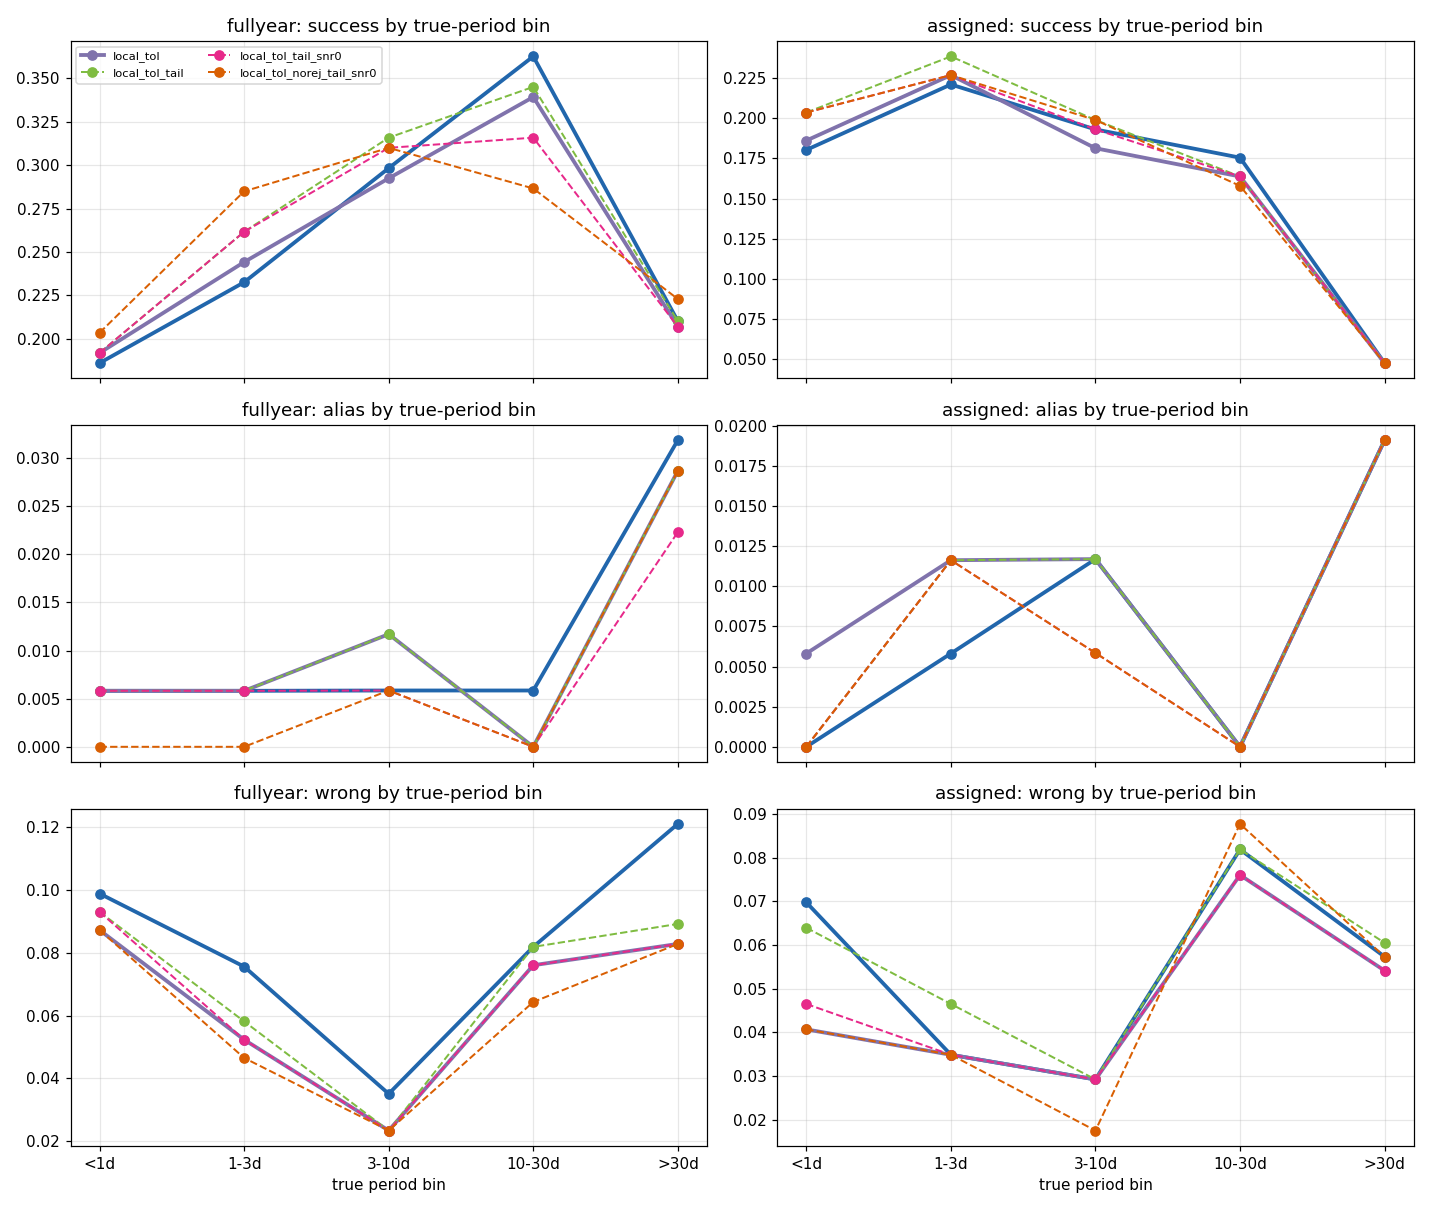

In [4]:
per_star = A.load_per_star()
A.fig_by_bin(per_star, [v for v in A.REFS + A.VARIANTS if (v, 'fullyear') in per_star])
display(Image(str(A.FIG / 'fig_by_bin.png')))

## frac_vertex_tol: all teeth vs positive-height teeth

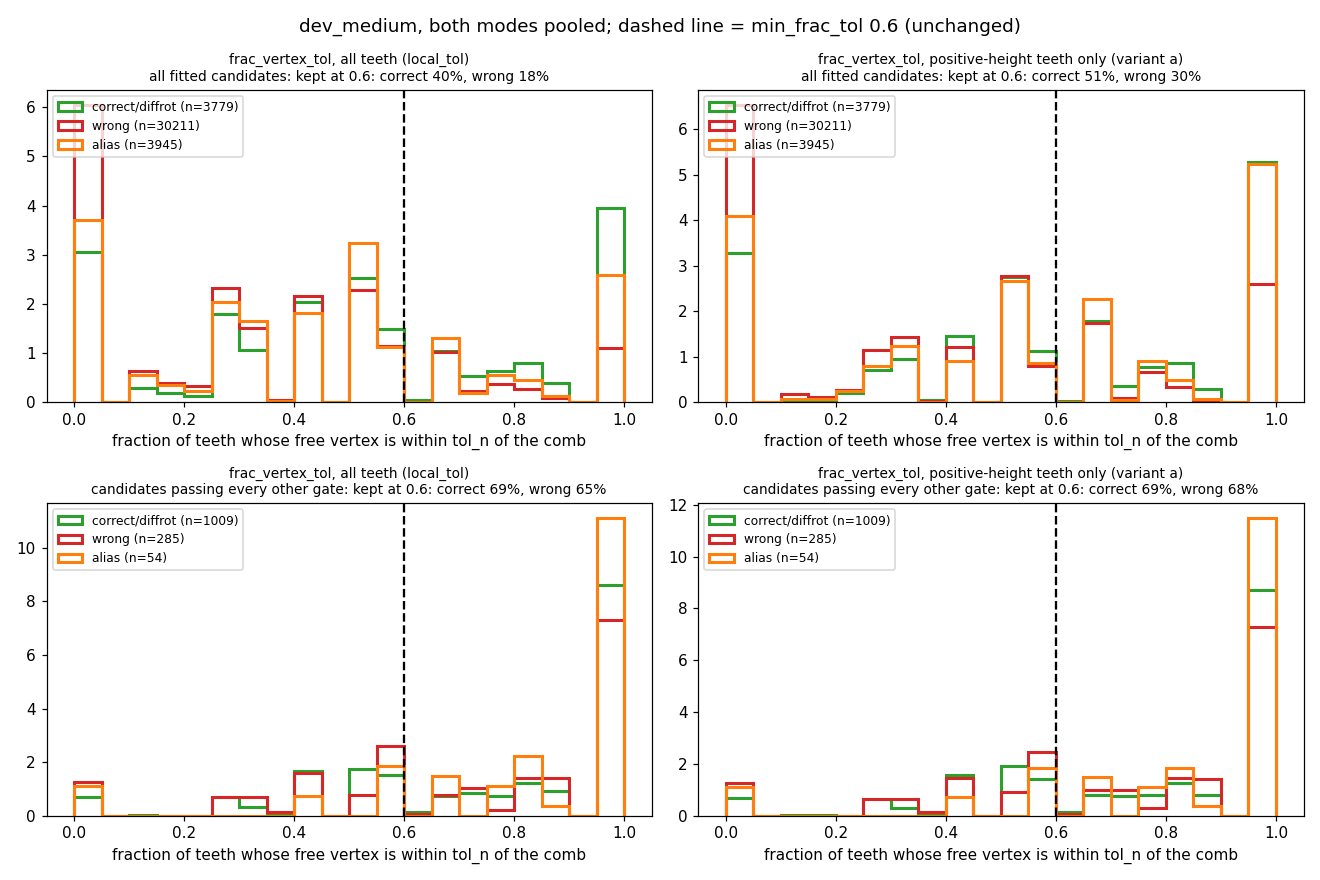

,subset,stat,group,n,kept
0,all fitted candidates,fvt_all,correct/diffrot,3779,0.401
1,all fitted candidates,fvt_all,wrong,30211,0.181
2,all fitted candidates,fvt_all,alias,3945,0.290
3,all fitted candidates,fvt_pos,correct/diffrot,3779,0.507
4,all fitted candidates,fvt_pos,wrong,30211,0.304
5,all fitted candidates,fvt_pos,alias,3945,0.487
6,candidates passing every other gate,fvt_all,correct/diffrot,1009,0.691
7,candidates passing every other gate,fvt_all,wrong,285,0.653
8,candidates passing every other gate,fvt_all,alias,54,0.870
9,candidates passing every other gate,fvt_pos,correct/diffrot,1009,0.695


In [5]:
c = pd.read_csv(A.DATA / 'cands_local_tol.csv.gz', dtype={'star_id': str})
A.fig_fvt(c)
display(Image(str(A.FIG / 'fig_fvt_all_vs_positive.png')))
display(pd.read_csv(A.DATA / 'fvt_stats.csv').round(3))

## local_tol's lost stars (vs _v7): which each variant recovers

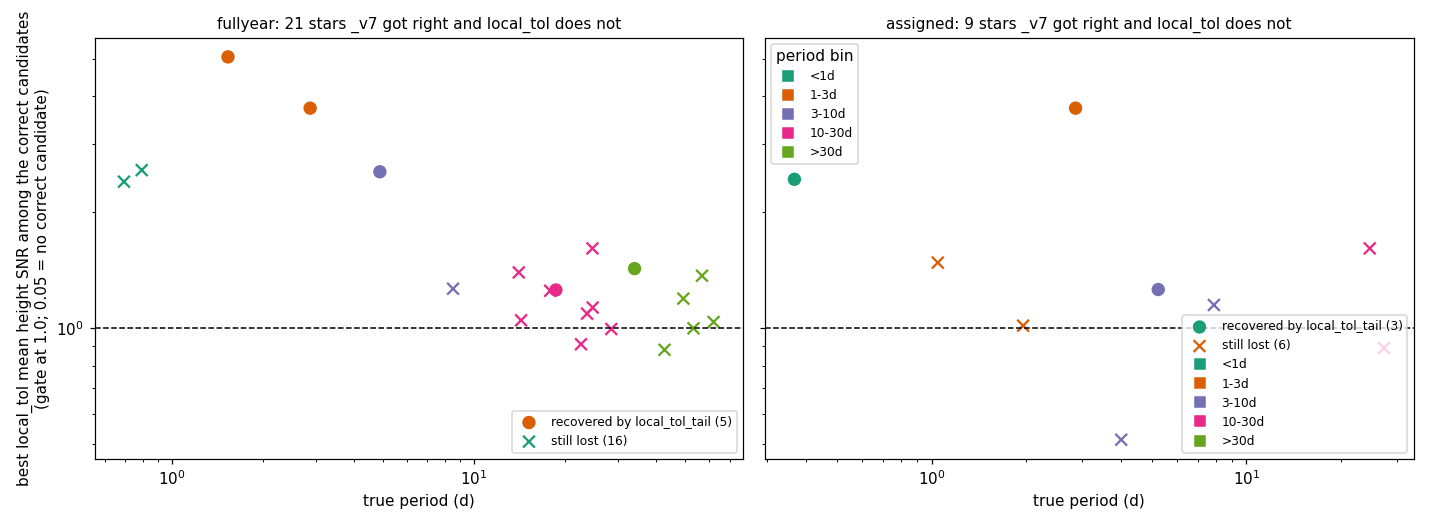

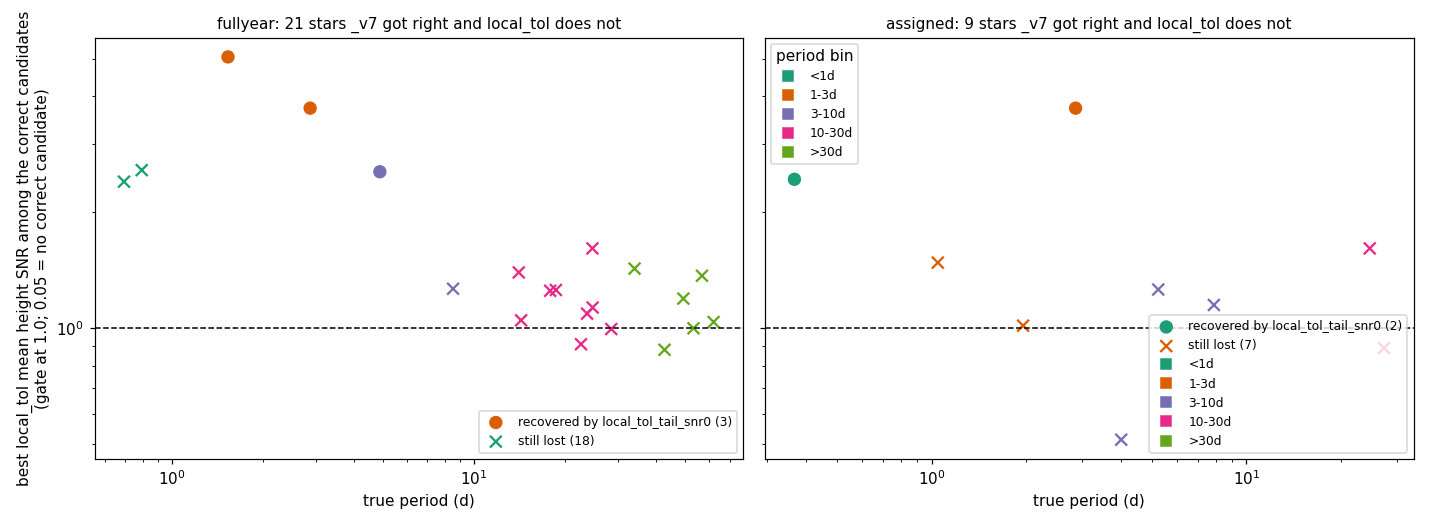

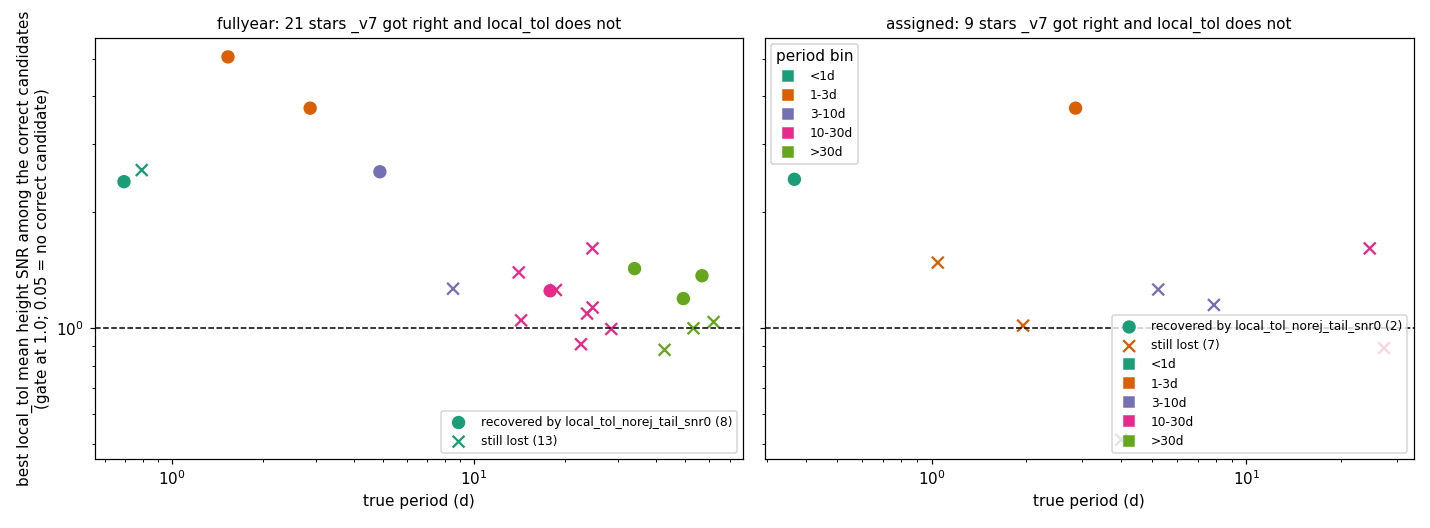

In [6]:
for v in A.VARIANTS:
    lt = A.lost_table(per_star, c, v); A.fig_lost_scatter(lt, v)
    display(Image(str(A.FIG / f'fig_lost_scatter_{v}.png')))

## Example stars (refits; needs data/smarts_dev and the Stage-1 cache)

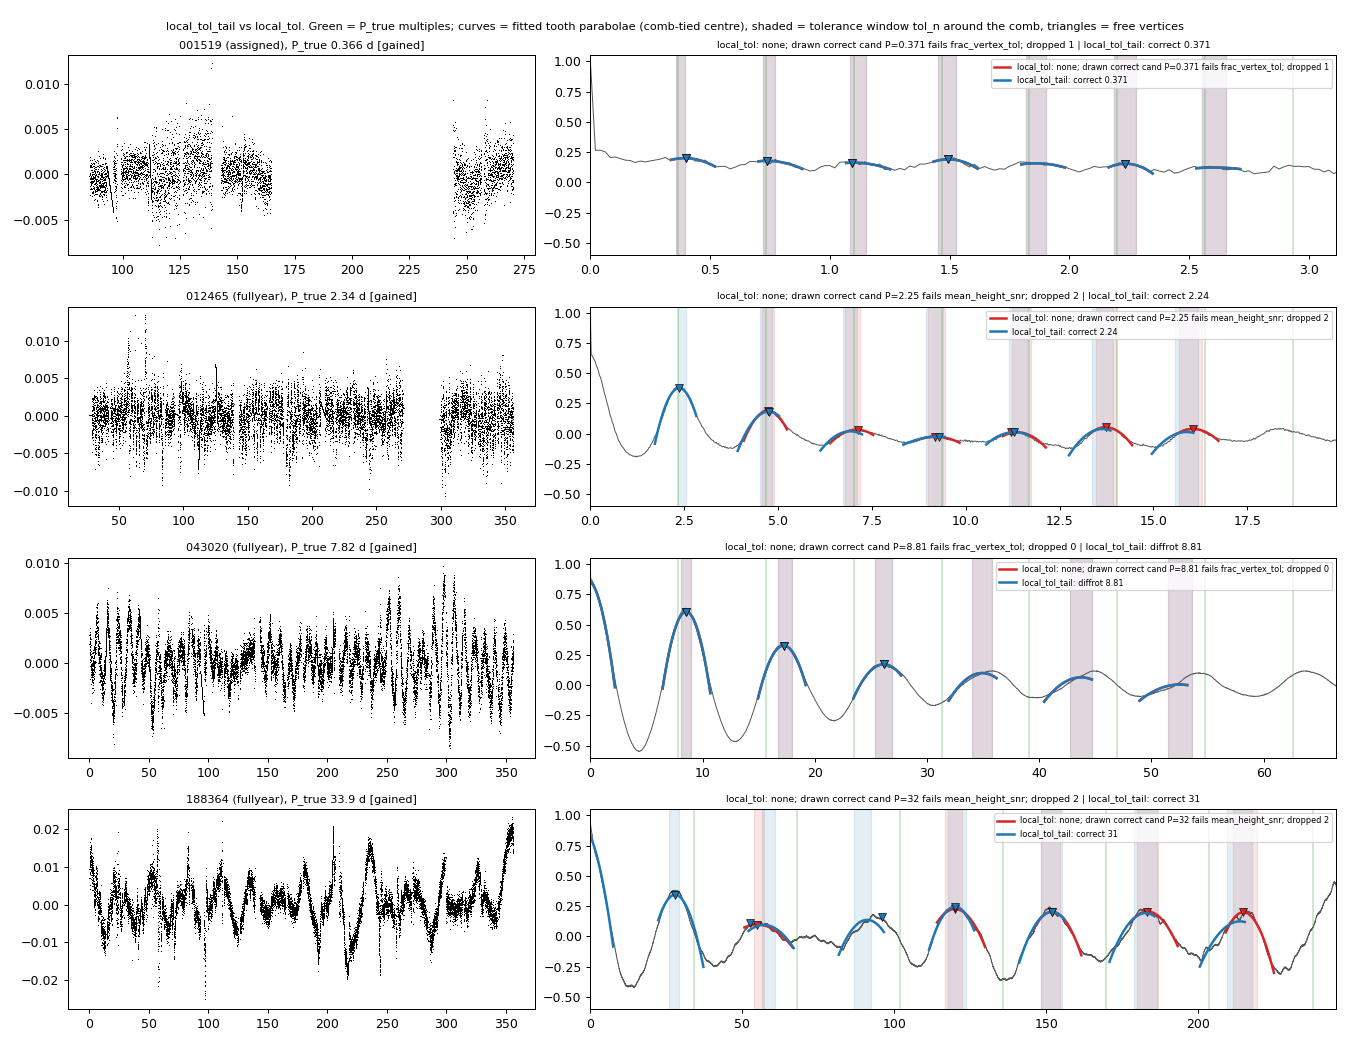

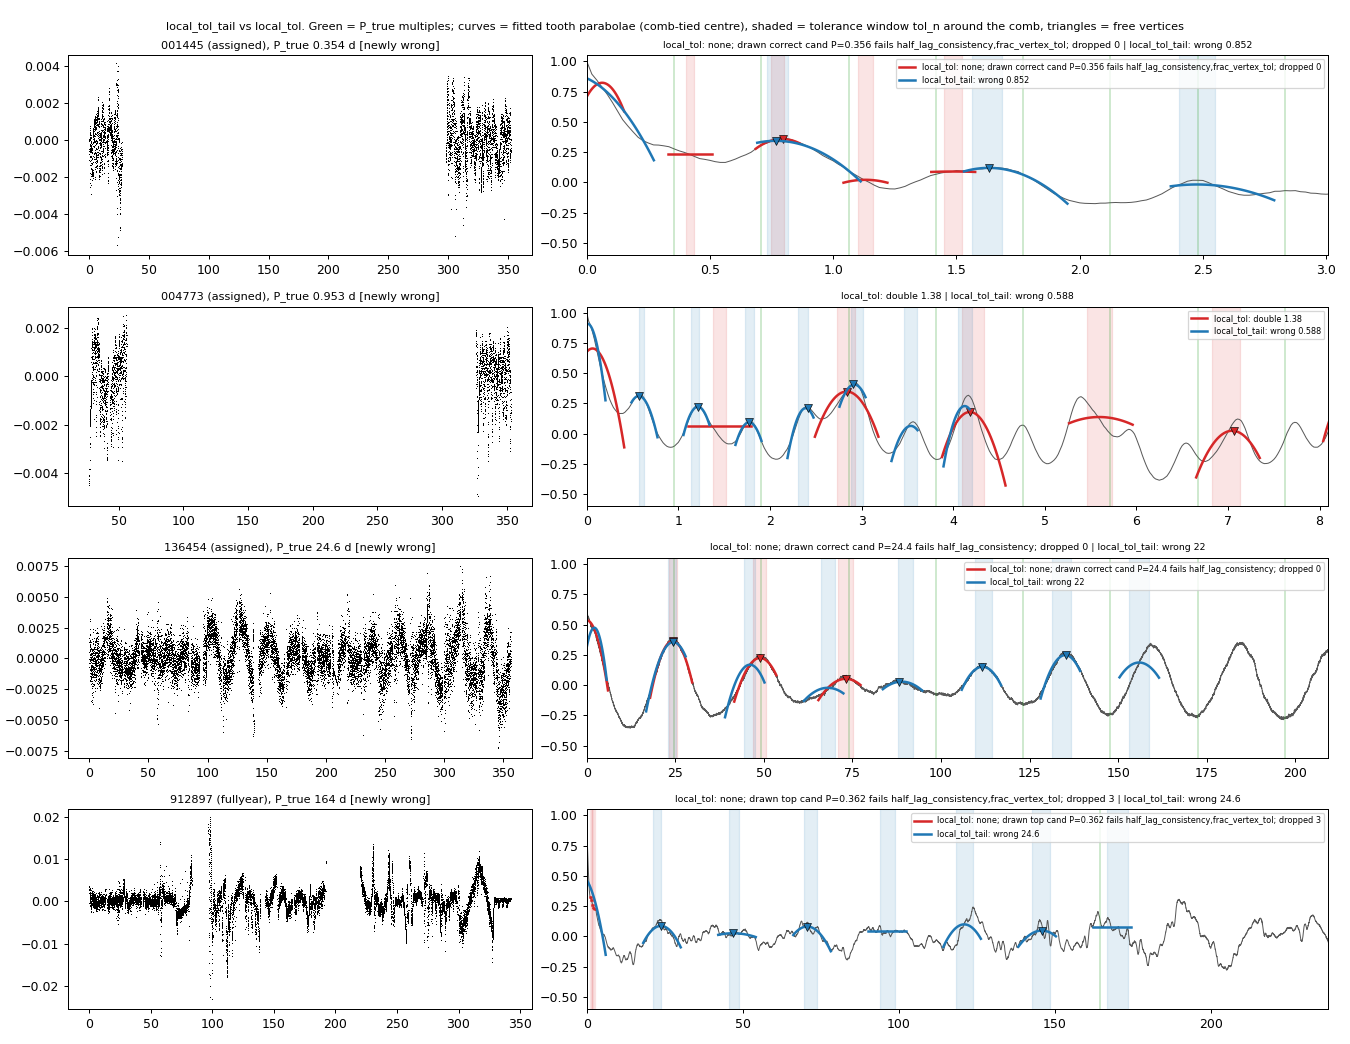

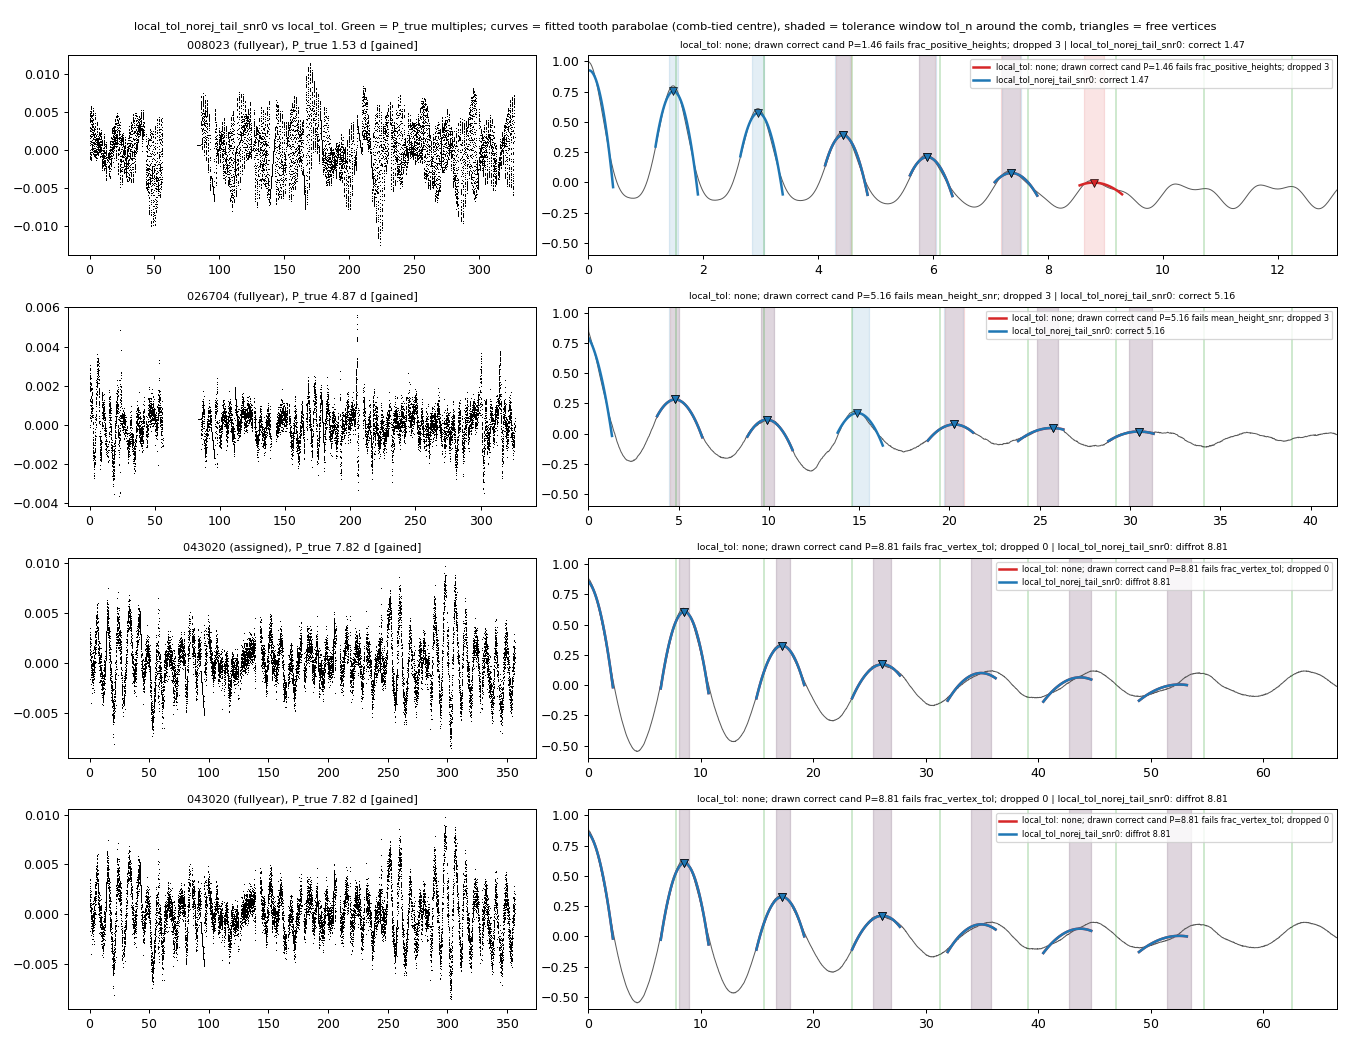

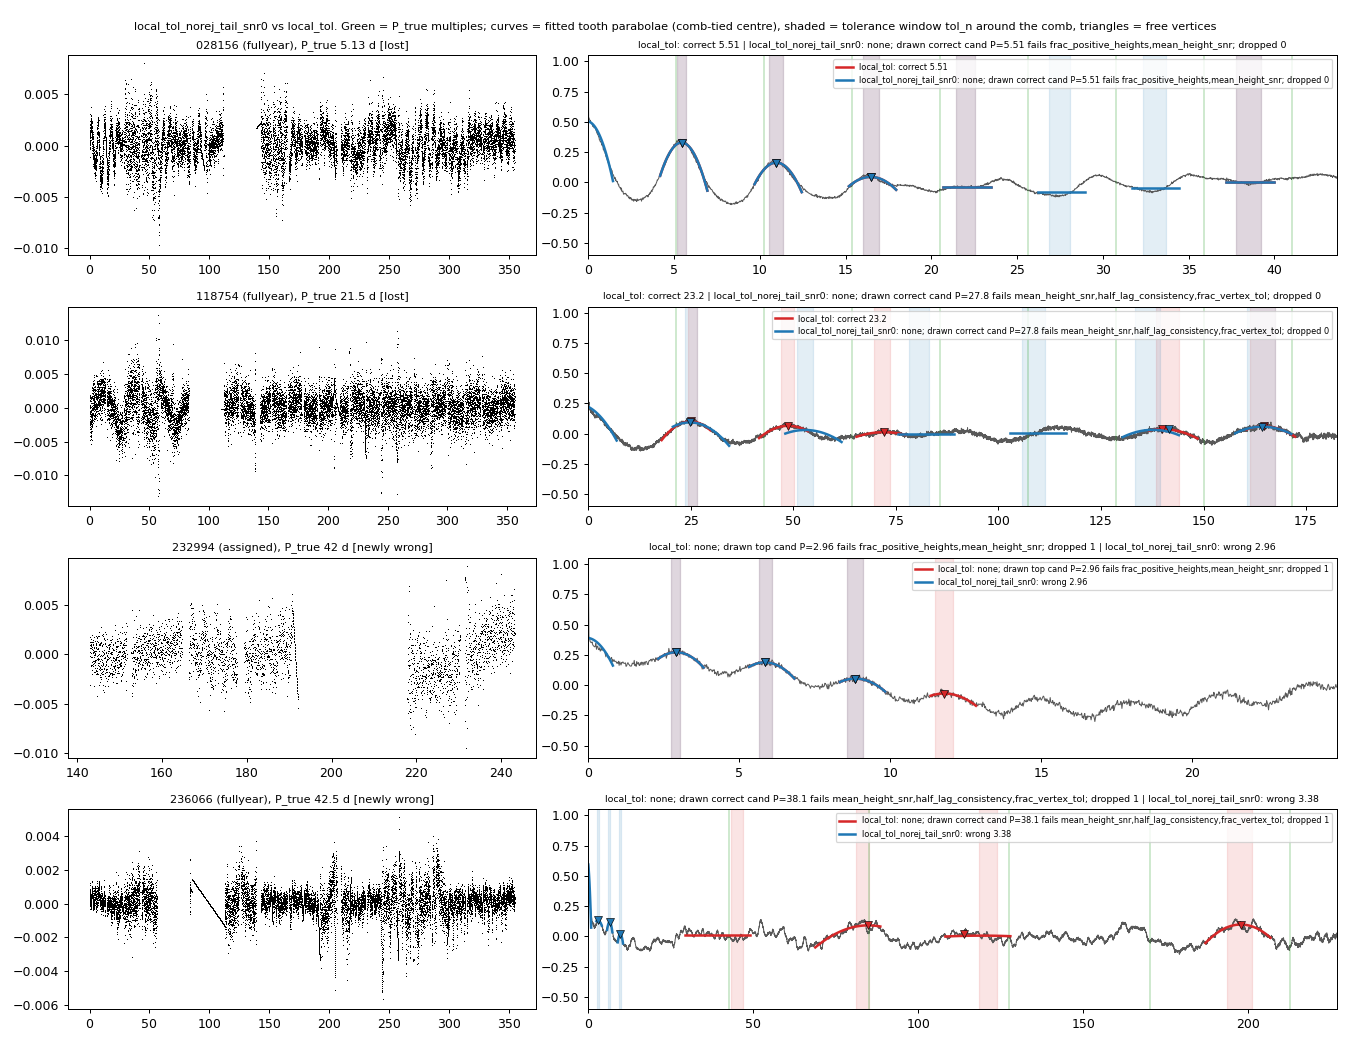

In [7]:
import numpy as np
for v in ('local_tol_tail', 'local_tol_norej_tail_snr0'):
    ch = A.changed_vs_tol(per_star, v)
    A.fig_examples(ch, v, ('gained',), f'fig_examples_{v}_recovered.png', n=4)
    bad = ch[(ch.change == 'lost') | ((ch.change == 'other') & (ch.final_outcome_var == 'wrong'))].copy()
    bad['change'] = np.where(bad.change == 'lost', 'lost', 'newly wrong')
    A.fig_examples(bad, v, ('lost', 'newly wrong'), f'fig_examples_{v}_lost_or_wrong.png', n=2 if (bad.change == 'lost').any() else 4)
    for k in ('recovered', 'lost_or_wrong'):
        display(Image(str(A.FIG / f'fig_examples_{v}_{k}.png')))

## drift_a_frac (the new ranker feature)

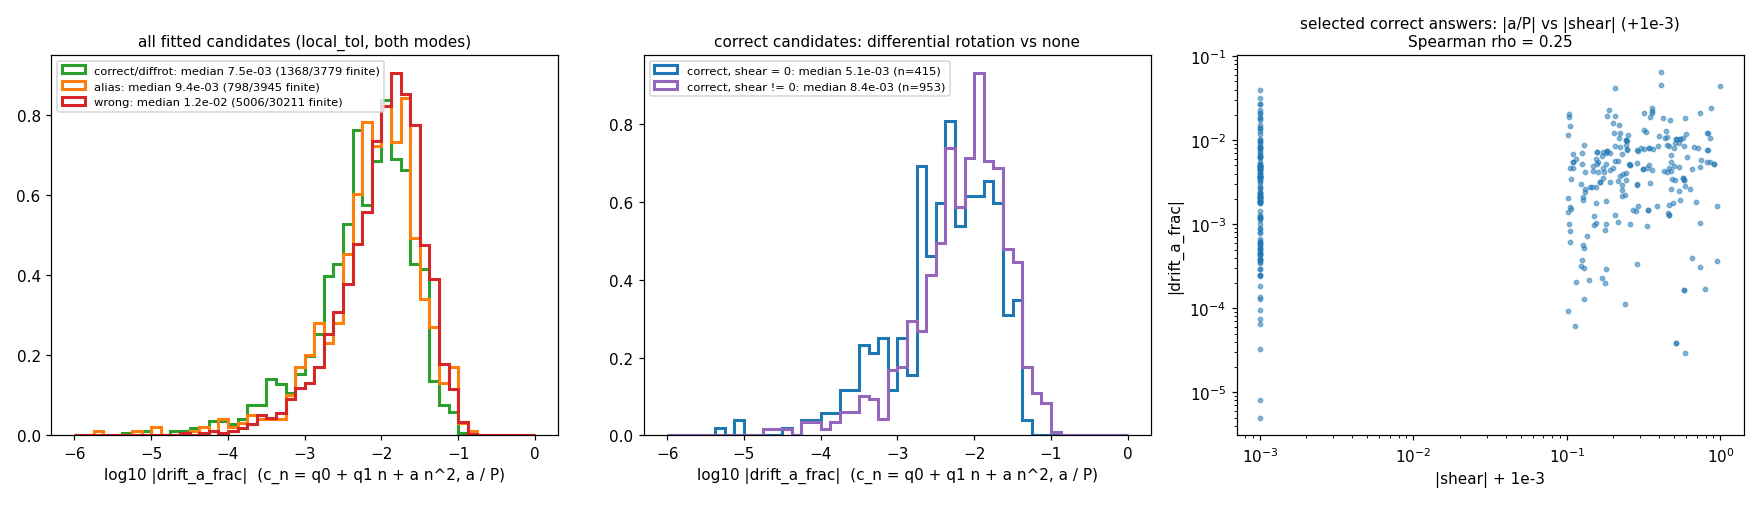

,group,n,n_finite,median_abs,q25,q75
0,correct/diffrot,3779,1368,0.007458,0.002895,0.016109
1,alias,3945,798,0.009448,0.004064,0.020038
2,wrong,30211,5006,0.012143,0.005129,0.023520
3,"correct, shear = 0",415,415,0.005105,0.001938,0.013205
4,"correct, shear != 0",953,953,0.008437,0.003349,0.017657


In [8]:
A.fig_drift(c)
display(Image(str(A.FIG / 'fig_drift_a_frac.png')))
display(pd.read_csv(A.DATA / 'drift_a_frac_summary.csv'))

## Runtime

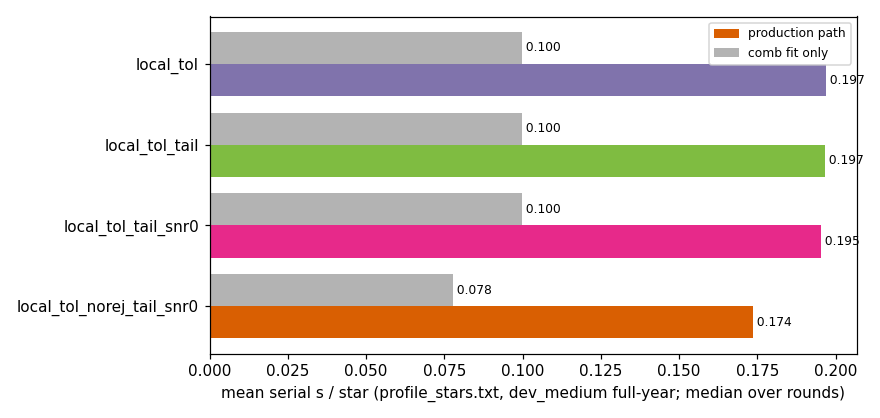

,variant,total,production,fit,features,n_rounds
0,local_tol,0.7290,0.1970,0.0996,0.1320,2
1,local_tol_norej_tail_snr0,0.7063,0.1736,0.0778,0.1319,2
2,local_tol_tail,0.7256,0.1967,0.0999,0.1310,2
3,local_tol_tail_snr0,0.7253,0.1952,0.0998,0.1316,2


In [9]:
tim = pd.read_csv(A.DATA / 'timing_summary.csv')
A.fig_runtime(tim)
display(Image(str(A.FIG / 'fig_runtime.png')))
display(tim.round(4))